# Métodos del mapa de investigación

Monitoreo indirecto de puentes con smartphones (*drive-by*): explicación de los **métodos** que aparecen en el mapa de investigación. El notebook sigue el orden del mapa, pero solo contiene información de métodos; solo aparecen los encabezados que ya tienen algún método.

<a id="indice"></a>
## Índice

- [2 Modal identification](#modal-identification)
  - [2.2 Mode shapes](#mode-shapes)
    - [2.2.2 Signal decomposition](#mode-shapes-signal-decomposition)
      - [2.2.2.1 EMD + Hilbert transform](#emd-hilbert)
      - [2.2.2.2 Wavelet transform (SSWT)](#wavelet-sswt)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import Wavelet, cwt, ssq_cwt
from ssqueezepy.experimental import scale_to_freq
from PyEMD import EMD
from scipy.interpolate import CubicSpline
from scipy.signal import argrelextrema, hilbert

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def morlet(t, w0=6.0):
    """Complex Morlet mother wavelet (Eq. 6): oscillation times a Gaussian bell."""
    return np.pi ** -0.25 * np.exp(1j * w0 * t) * np.exp(-t ** 2 / 2)


def scale_for_freq(f, w0=6.0):
    """Scale a whose wavelet oscillates at frequency f in Hz (Eq. 7 solved for a)."""
    return w0 / (2 * np.pi * f)


def scaled_wavelet(t, a, b, w0=6.0):
    """Mother wavelet stretched by scale a and shifted to time b (kernel of Eq. 8)."""
    return morlet((t - b) / a, w0) / np.sqrt(a)


def instantaneous_attributes(c, fs):
    """Envelope A(t) and instantaneous frequency f(t) in Hz of an IMF (Eqs. 4-5)."""
    z = hilbert(c)                      # analytic signal c + i H[c]
    amplitude = np.abs(z)
    phase = np.unwrap(np.angle(z))
    freq = np.gradient(phase) * fs / (2 * np.pi)
    return amplitude, freq

---

<a id="modal-identification"></a>
## 2 Modal identification

---

<a id="mode-shapes"></a>
### 2.2 Mode shapes

<a id="mode-shapes-signal-decomposition"></a>
#### 2.2.2 Signal decomposition

<a id="emd-hilbert"></a>
##### 2.2.2.1 EMD + Hilbert transform

**Qué es**

- La EMD (*Empirical Mode Decomposition*, descomposición empírica en modos) separa una señal en componentes llamadas IMF (*Intrinsic Mode Functions*, funciones de modo intrínseco), de la oscilación más rápida a la más lenta, más una tendencia final.
- Es **adaptativa**: no usa una base fija (como el seno de Fourier o la wavelet madre); las componentes salen de la propia señal.
- La **transformada de Hilbert** se aplica después a cada IMF para obtener su amplitud y su frecuencia en cada instante.
- Juntas forman la transformada de Hilbert-Huang (HHT, *Hilbert-Huang transform*).

**Qué es una IMF** (dos condiciones)

1. El número de extremos y el número de cruces por cero difieren como máximo en uno.
2. En cada instante, la media entre la envolvente superior y la inferior es cero.

Con eso, cada IMF es una oscilación "limpia", parecida a un seno, pero con amplitud y frecuencia que pueden cambiar en el tiempo.

**Para qué se aplica**

- En señales **no lineales y no estacionarias**, donde las frecuencias o amplitudes cambian en el tiempo.
- En *drive-by*: para aislar la componente de un modo del puente y seguir cómo cambia su amplitud mientras el vehículo avanza.

**Cómo funciona**

EMD (proceso de *sifting*, "cernido"):

1. Se buscan los máximos y mínimos locales de la señal.
2. Se unen los máximos con un spline cúbico (envolvente superior) y los mínimos con otro (envolvente inferior).
3. Se calcula la media de las dos envolventes y se resta de la señal.
4. Se repite sobre el resultado hasta que cumpla las condiciones de IMF (criterio de parada). Esa es la primera IMF, la más rápida.
5. Se resta la IMF de la señal original y se repite todo sobre lo que queda (el residuo), para sacar la siguiente IMF, más lenta.
6. Se para cuando el residuo ya no oscila (es monótono): esa es la tendencia.

Hilbert:

7. A cada IMF se le aplica la transformada de Hilbert, que desfasa cada componente un cuarto de periodo ($\pi/2$).
8. Con la IMF y su transformada se forma la señal analítica, de donde salen la amplitud instantánea (envolvente) y la frecuencia instantánea.

*Resultado de la EMD (pasos 1–6).*

$$x(t)=\sum_{i=1}^{n} c_i(t) + r_n(t) \tag{1}$$

- $x(t)$: señal medida.
- $c_i(t)$: la IMF número $i$ ($i=1$ es la más rápida).
- $n$: número de IMFs.
- $r_n(t)$: residuo final o tendencia (ya no oscila).

En palabras: la señal es exactamente la suma de sus IMFs más la tendencia; la EMD no pierde nada, solo reparte la señal en capas.

*Un paso de sifting (pasos 2–3).*

$$m(t)=\frac{e_{\max}(t)+e_{\min}(t)}{2},\qquad h(t)=x(t)-m(t) \tag{2}$$

- $e_{\max}(t)$: envolvente superior (spline cúbico por los máximos).
- $e_{\min}(t)$: envolvente inferior (spline cúbico por los mínimos).
- $m(t)$: media de las dos envolventes.
- $h(t)$: candidato a IMF, lo que queda al quitar la media.

En palabras: se quita a la señal la línea que pasa por el centro de sus oscilaciones; lo que queda oscila alrededor de cero.

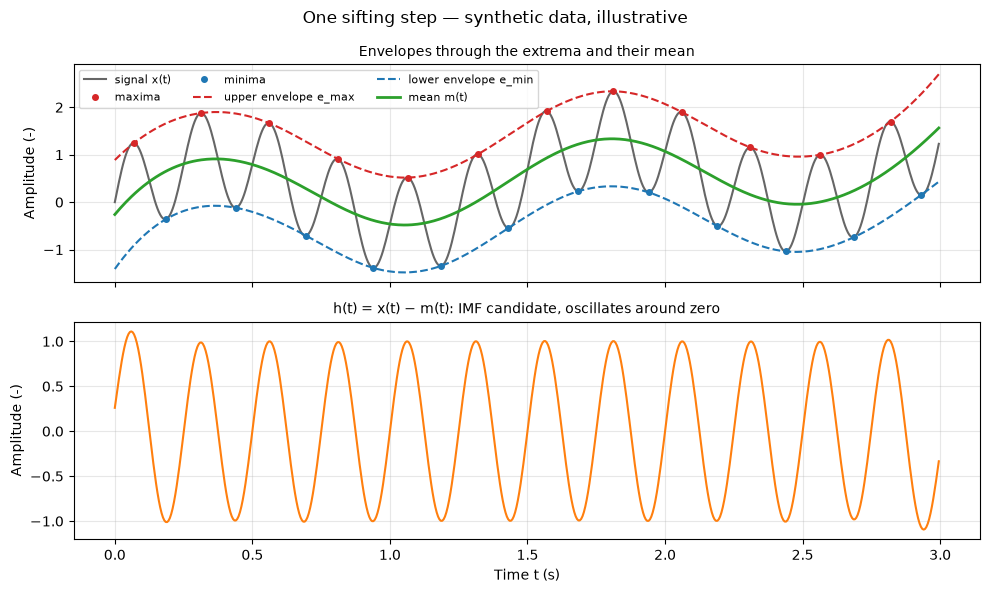

In [2]:
# One sifting step on a synthetic signal (illustrative)
fs_s = 200.0                            # sampling rate, Hz
t_s = np.arange(0, 3, 1 / fs_s)         # time, s
x_s = np.sin(2 * np.pi * 4 * t_s) + 0.8 * np.sin(2 * np.pi * 0.7 * t_s) + 0.3 * t_s

i_max = argrelextrema(x_s, np.greater)[0]     # local maxima
i_min = argrelextrema(x_s, np.less)[0]        # local minima
e_max = CubicSpline(t_s[i_max], x_s[i_max])(t_s)   # upper envelope
e_min = CubicSpline(t_s[i_min], x_s[i_min])(t_s)   # lower envelope
m_s = (e_max + e_min) / 2                     # mean envelope (Eq. 2)
h_s = x_s - m_s                               # IMF candidate (Eq. 2)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax = axes[0]
ax.plot(t_s, x_s, color="0.4", label="signal x(t)")
ax.plot(t_s[i_max], x_s[i_max], "o", color="C3", ms=4, label="maxima")
ax.plot(t_s[i_min], x_s[i_min], "o", color="C0", ms=4, label="minima")
ax.plot(t_s, e_max, "--", color="C3", label="upper envelope e_max")
ax.plot(t_s, e_min, "--", color="C0", label="lower envelope e_min")
ax.plot(t_s, m_s, color="C2", lw=2, label="mean m(t)")
ax.set_ylabel("Amplitude (-)")
ax.set_title("Envelopes through the extrema and their mean", fontsize=10)
ax.legend(loc="upper left", fontsize=8, ncol=3)
axes[1].plot(t_s, h_s, color="C1")
axes[1].set_ylabel("Amplitude (-)")
axes[1].set_xlabel("Time t (s)")
axes[1].set_title("h(t) = x(t) − m(t): IMF candidate, oscillates around zero", fontsize=10)
fig.suptitle("One sifting step — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 1.** Un paso de *sifting* sobre una señal sintética (ilustrativo): arriba, la señal con sus máximos y mínimos, las dos envolventes (splines cúbicos) y su media; abajo, la señal menos la media, que ya oscila alrededor de cero. Cerca de los bordes las envolventes se doblan porque no hay extremos más allá: es el efecto de borde.

*Descomposición completa (pasos 4–6).* Repitiendo el *sifting* hasta cumplir las condiciones de IMF, y luego sobre cada residuo, se obtiene la Ec. 1. La señal de prueba suma una oscilación rápida de 8 Hz con amplitud variable, una lenta de 1.2 Hz, una tendencia lineal y ruido.

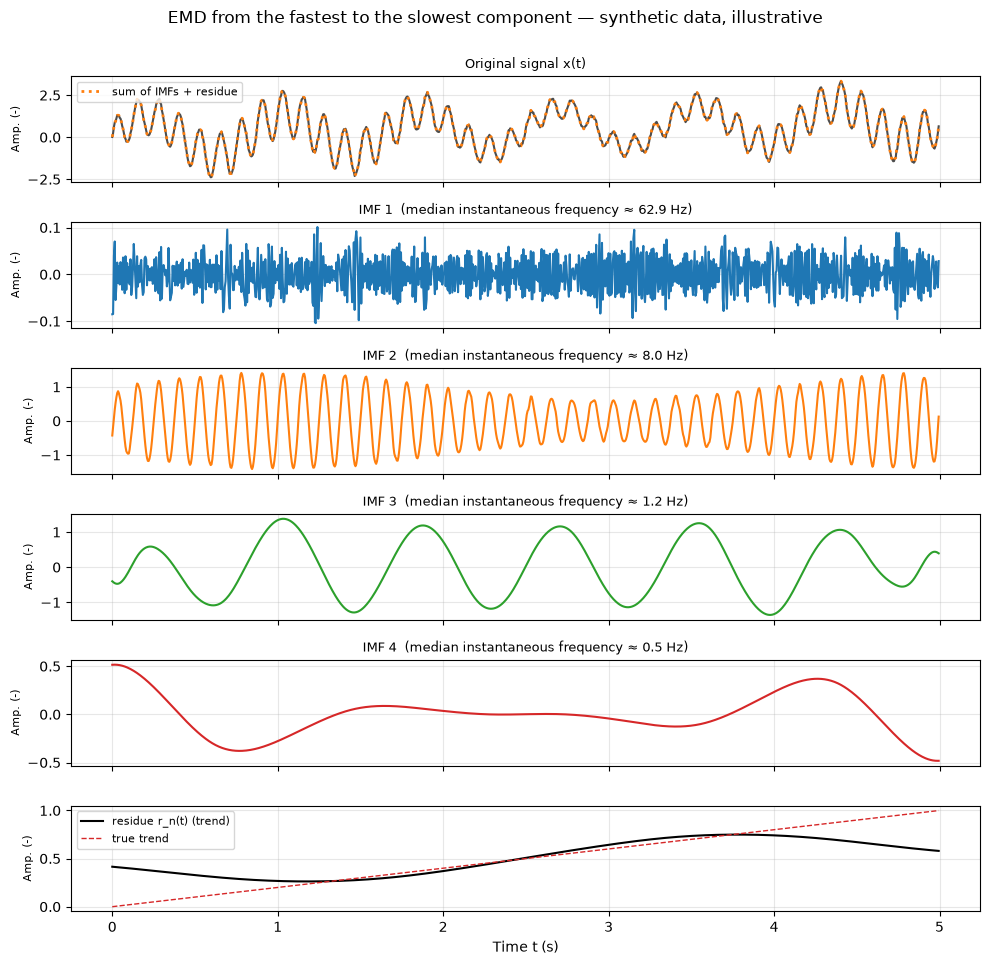

Number of IMFs: 4
Max reconstruction error |x - (sum c_i + r_n)|: 1.1e-16


In [3]:
# Full EMD of a synthetic signal (illustrative)
rng_emd = np.random.default_rng(SEED)   # own generator: keeps the other sections unchanged
fs_e = 200.0                            # sampling rate, Hz
t_e = np.arange(0, 5, 1 / fs_e)         # time, s
fast = (1 + 0.4 * np.sin(2 * np.pi * 0.25 * t_e)) * np.sin(2 * np.pi * 8 * t_e)   # 8 Hz, varying amplitude
slow = 1.2 * np.sin(2 * np.pi * 1.2 * t_e)                                        # 1.2 Hz
trend = 0.2 * t_e
x_e = fast + slow + trend + 0.05 * rng_emd.standard_normal(t_e.size)

emd = EMD()
emd.emd(x_e, t_e)
imfs, residue = emd.get_imfs_and_residue()
n_imf = imfs.shape[0]
reconstruction = imfs.sum(axis=0) + residue    # Eq. 1

fig, axes = plt.subplots(n_imf + 2, 1, figsize=(10, 1.6 * (n_imf + 2)), sharex=True)
axes[0].plot(t_e, x_e, color="0.3")
axes[0].set_title("Original signal x(t)", fontsize=9)
for i in range(n_imf):
    _, f_i = instantaneous_attributes(imfs[i], fs_e)
    axes[i + 1].plot(t_e, imfs[i], color=f"C{i}")
    axes[i + 1].set_title(f"IMF {i + 1}  (median instantaneous frequency ≈ {np.median(f_i):.1f} Hz)", fontsize=9)
axes[-1].plot(t_e, residue, color="k", label="residue r_n(t) (trend)")
axes[-1].plot(t_e, trend, "--", color="C3", lw=1, label="true trend")
axes[-1].legend(loc="upper left", fontsize=8)
for ax in axes:
    ax.set_ylabel("Amp. (-)", fontsize=8)
axes[-1].set_xlabel("Time t (s)")
axes[0].plot(t_e, reconstruction, ":", color="C1", lw=2, label="sum of IMFs + residue")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("EMD from the fastest to the slowest component — synthetic data, illustrative", y=1.0)
fig.tight_layout()
plt.show()
print(f"Number of IMFs: {n_imf}")
print(f"Max reconstruction error |x - (sum c_i + r_n)|: {np.max(np.abs(x_e - reconstruction)):.1e}")

**Figura 2.** EMD de una señal sintética (ilustrativo): de arriba abajo, la señal original (con la reconstrucción punteada encima), las IMFs de la más rápida a la más lenta y el residuo comparado con la tendencia verdadera.

- La IMF 1 recoge el ruido, la IMF 2 la oscilación de 8 Hz y la IMF 3 la de 1.2 Hz. La IMF 4 es una oscilación lenta y pequeña que sobra de la tendencia y de los bordes.
- El residuo se aparta de la tendencia verdadera porque parte de ella quedó en la IMF 4: es un caso de mezcla de modos, que se repite en señales cortas.
- La suma de todas las IMFs más el residuo reproduce la señal original (error del orden de la precisión numérica): es la Ec. 1.

*Hilbert (pasos 7–8).*

$$\mathcal{H}[c](t)=\frac{1}{\pi}\,\mathrm{PV}\!\int_{-\infty}^{\infty}\frac{c(\tau)}{t-\tau}\,d\tau \tag{3}$$

- $\mathcal{H}[c](t)$: transformada de Hilbert de la IMF $c$ en el instante $t$.
- $c(\tau)$: la IMF, evaluada en cada instante $\tau$ de la integral.
- $\mathrm{PV}$: valor principal de Cauchy; la integral se evalúa excluyendo simétricamente el punto $\tau=t$, donde el denominador se anula.
- $1/\pi$: constante de normalización.

En palabras: produce una copia de la IMF desfasada un cuarto de periodo ($\pi/2$) en cada componente; un coseno se vuelve seno.

$$z(t)=c(t)+i\,\mathcal{H}[c](t)=A(t)\,e^{i\theta(t)} \tag{4}$$

$$A(t)=\sqrt{c(t)^2+\mathcal{H}[c](t)^2},\qquad f(t)=\frac{1}{2\pi}\frac{d\theta}{dt} \tag{5}$$

- $z(t)$: señal analítica (compleja): la IMF como parte real y su transformada de Hilbert como parte imaginaria.
- $i$: unidad imaginaria.
- $A(t)$: amplitud instantánea o envolvente.
- $\theta(t)$: fase instantánea, en rad.
- $f(t)$: frecuencia instantánea, en Hz.

En palabras: la IMF y su copia desfasada son como las dos coordenadas de un punto que gira; el radio del giro es la amplitud y la velocidad del giro es la frecuencia, en cada instante.

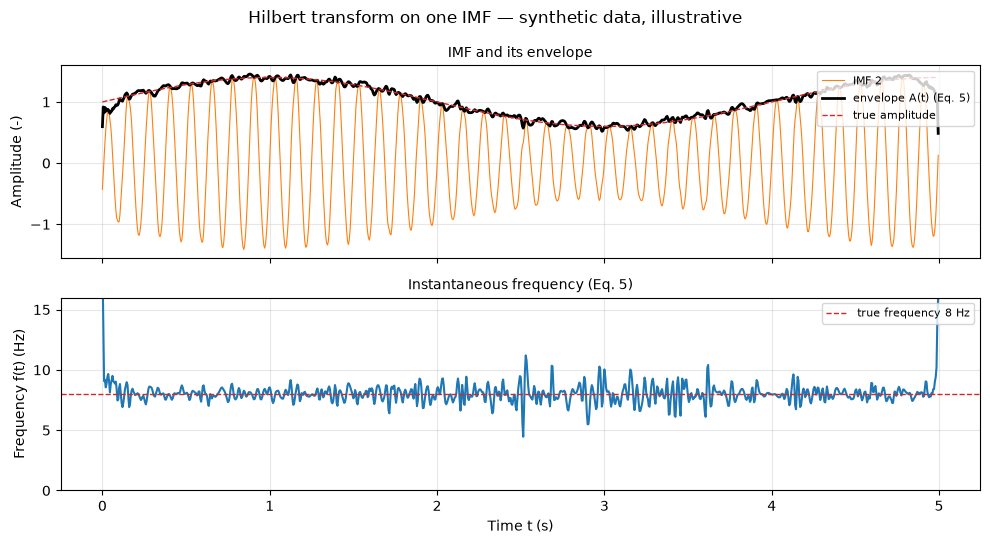

In [4]:
# Hilbert transform on the 8 Hz IMF of Fig. 2 (illustrative)
f_target = 8.0
medians = [np.median(instantaneous_attributes(c, fs_e)[1]) for c in imfs]
k_fast = int(np.argmin(np.abs(np.array(medians) - f_target)))   # IMF closest to 8 Hz
amp_fast, freq_fast = instantaneous_attributes(imfs[k_fast], fs_e)
true_env = 1 + 0.4 * np.sin(2 * np.pi * 0.25 * t_e)

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(t_e, imfs[k_fast], color="C1", lw=0.8, label=f"IMF {k_fast + 1}")
axes[0].plot(t_e, amp_fast, color="k", lw=2, label="envelope A(t) (Eq. 5)")
axes[0].plot(t_e, true_env, "--", color="C3", lw=1, label="true amplitude")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("IMF and its envelope", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(t_e, freq_fast, color="C0")
axes[1].axhline(f_target, color="C3", ls="--", lw=1, label="true frequency 8 Hz")
axes[1].set_ylim(0, 16)
axes[1].set_ylabel("Frequency f(t) (Hz)")
axes[1].set_xlabel("Time t (s)")
axes[1].set_title("Instantaneous frequency (Eq. 5)", fontsize=10)
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Hilbert transform on one IMF — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 3.** Transformada de Hilbert sobre la IMF de 8 Hz (ilustrativo): arriba, la IMF con su envolvente $A(t)$, que sigue la amplitud verdadera; abajo, la frecuencia instantánea $f(t)$, que se mantiene cerca de 8 Hz.

- En los extremos la frecuencia se dispara y la envolvente se deforma: es el efecto de borde de la EMD y de la transformada de Hilbert.

**Cómo se usa para la forma modal** (referencia: Malekjafarian y OBrien, 2017)

- Se escoge la IMF cuya frecuencia instantánea se mantiene cerca de la frecuencia del modo buscado (en el artículo, la frecuencia a la que se sintonizó un excitador en el vehículo).
- Su amplitud instantánea, expresada contra la posición del vehículo, indica cuánto se mueve ese modo en cada punto.
- En el artículo, la envolvente se suaviza con un promedio móvil y se recortan los extremos. Luego se usa en el reescalado entre ejes para construir la forma modal (eso es otro paso del mapa, 2.2.4; aquí solo se menciona).

**Ejemplo sintético.** Un vehículo cruza una viga simplemente apoyada de $L=15$ m a $v=2$ m/s (cruce de 7.5 s). La señal es:

$x(t)=|\phi(v\,t)|\cos(2\pi f_b t)+\text{componente del vehículo}+\text{ruido}$

- $f_b=5.65$ Hz y $\phi(x)=\sin(\pi x/L)$: primer modo de la viga.
- La componente del vehículo es una oscilación de 1.5 Hz (valor inventado para el ejemplo).
- La luz, la velocidad y $f_b$ coinciden con el caso que estudia el artículo, pero la señal es sintética: no reproduce sus datos ni sus resultados.
- Promedio móvil de 0.5 s y recorte de 0.5 s (1 m) en cada extremo: valores escogidos para el ejemplo.

Median instantaneous frequency of each IMF (Hz): [32.07  5.7   1.51  0.98  0.52]
Selected IMF: 2 (closest to f_b = 5.65 Hz)
RMS error vs |phi| on the trimmed part: 0.047


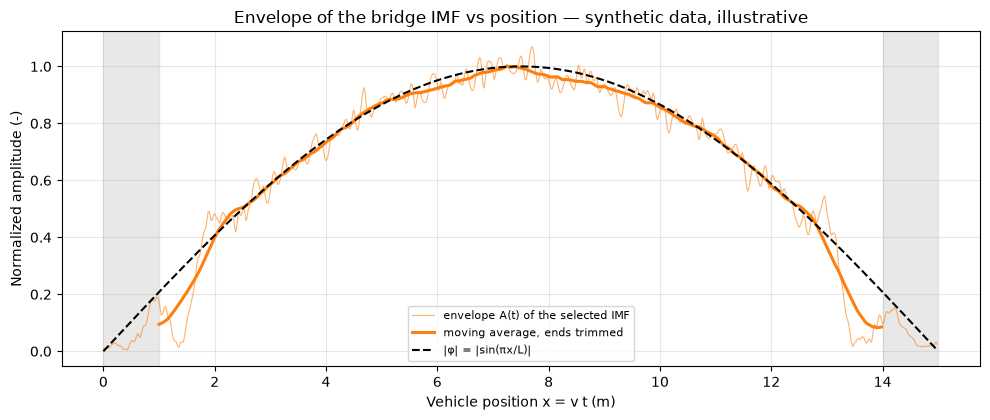

In [5]:
# Drive-by example: 15 m simply supported beam crossed at 2 m/s (illustrative)
rng_db = np.random.default_rng(SEED)
L_b = 15.0                              # span length, m
v_b = 2.0                               # vehicle speed, m/s
f_b = 5.65                              # bridge mode 1 frequency, Hz
f_veh = 1.5                             # vehicle component frequency, Hz (made up)
fs_b = 100.0                            # sampling rate, Hz

t_b = np.arange(0, L_b / v_b, 1 / fs_b) # time, s
pos_b = v_b * t_b                       # vehicle position, m
phi_b = np.sin(np.pi * pos_b / L_b)     # mode 1 shape
x_b = (np.abs(phi_b) * np.cos(2 * np.pi * f_b * t_b)
       + 0.8 * np.sin(2 * np.pi * f_veh * t_b)
       + 0.05 * rng_db.standard_normal(t_b.size))

emd_b = EMD()
emd_b.emd(x_b, t_b)
imfs_b, _ = emd_b.get_imfs_and_residue()
medians_b = np.array([np.median(instantaneous_attributes(c, fs_b)[1]) for c in imfs_b])
k_b = int(np.argmin(np.abs(medians_b - f_b)))          # IMF closest to the bridge frequency
amp_b, _ = instantaneous_attributes(imfs_b[k_b], fs_b)

win = int(0.5 * fs_b)                                  # moving-average window: 0.5 s
amp_smooth = np.convolve(amp_b, np.ones(win) / win, mode="same")
inner = slice(win, -win)                               # trim 0.5 s at each end
amp_norm = amp_smooth / amp_smooth[inner].max()

print("Median instantaneous frequency of each IMF (Hz):", np.round(medians_b, 2))
print(f"Selected IMF: {k_b + 1} (closest to f_b = {f_b} Hz)")
rms = np.sqrt(np.mean((amp_norm[inner] - np.abs(phi_b[inner])) ** 2))
print(f"RMS error vs |phi| on the trimmed part: {rms:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos_b, amp_b / amp_smooth[inner].max(), color="C1", lw=0.8, alpha=0.6, label="envelope A(t) of the selected IMF")
ax.plot(pos_b[inner], amp_norm[inner], color="C1", lw=2.2, label="moving average, ends trimmed")
ax.plot(pos_b, np.abs(phi_b), "k--", lw=1.5, label="|φ| = |sin(πx/L)|")
for edge in [(0, pos_b[win]), (pos_b[-win], L_b)]:
    ax.axvspan(*edge, color="0.85", alpha=0.6)
ax.set_xlabel("Vehicle position x = v t (m)")
ax.set_ylabel("Normalized amplitude (-)")
ax.set_title("Envelope of the bridge IMF vs position — synthetic data, illustrative")
ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 4.** Envolvente de la IMF del puente contra la posición del vehículo, comparada con $|\phi|$ (ilustrativo, datos sintéticos): la EMD separa el modo de 5.65 Hz de la componente del vehículo, y su envolvente suavizada sigue la forma del primer modo. Las franjas grises son los extremos recortados, donde actúa el efecto de borde.

- La envolvente no tiene signo; con el primer modo no se nota porque $\phi$ es positiva en toda la luz.

**Ventajas**

- Adaptativa: no necesita escoger una base ni una wavelet madre.
- Funciona con señales no lineales y no estacionarias.
- Da amplitud y frecuencia en cada instante, con muy buena resolución en el tiempo.

**Desventajas**

- **Mezcla de modos:** una IMF puede contener oscilaciones de escalas distintas, o una misma oscilación puede repartirse entre dos IMFs.
- **Efectos de borde:** los splines se deforman en los extremos de la señal (por eso en el artículo se recortan los extremos).
- Sensible al ruido; el resultado depende del criterio de parada.
- No tiene una base matemática cerrada; es un algoritmo empírico.
- Hilbert solo da una frecuencia con sentido físico si la IMF tiene una sola componente (banda estrecha).
- Para formas modales hay que saber qué frecuencia buscar.
- Existen variantes que reducen la mezcla de modos, como EEMD (*Ensemble EMD*) y CEEMDAN (*Complete Ensemble EMD with Adaptive Noise*).

**Pregunta abierta**

> La EMD da IMFs parecidas a ondas seno, y por eso Hilbert funciona. Pero una señal real viene de muchas fuentes, y no todas son de tipo seno. Si alguna no lo es, ¿queda en el residuo o se mezcla en las IMFs y las distorsiona?

**Artículos:** Malekjafarian y OBrien (2017).

> **Nota de fuentes.** La explicación general de la EMD, las condiciones de IMF, la transformada de Hilbert, la mezcla de modos y las variantes EEMD/CEEMDAN es conocimiento general, no del artículo. Del artículo vienen: la descomposición en IMFs de la más rápida a la más lenta, el uso de Hilbert para la frecuencia instantánea y la selección de la IMF cercana a la frecuencia de excitación, y la envolvente contra la posición suavizada con promedio móvil y recortada en los extremos.

**Entradas y salidas**

- **Entrada:**
  - Una señal de aceleración contra tiempo, de un solo canal, con su frecuencia de muestreo.
  - El criterio de parada del *sifting* y, si se quiere, el número máximo de IMFs.
  - Para formas modales, además: la posición del vehículo en cada instante y la frecuencia del modo que se busca.
- **Salida:**
  - Un conjunto de IMFs $c_i(t)$ más un residuo.
  - Para cada IMF, su amplitud instantánea $A_i(t)$ y su frecuencia instantánea $f_i(t)$.
- **Qué se obtiene o interpreta:**
  - Qué oscilaciones componen la señal y cómo cambia la frecuencia de cada una en el tiempo.
  - Cuál IMF corresponde al modo del puente (la que se mantiene cerca de su frecuencia).
  - La envolvente de esa IMF contra la posición: cómo cambia la amplitud del modo a lo largo del puente, que es la base para construir la forma modal.

[↑ Volver al índice](#indice)

<a id="wavelet-sswt"></a>
##### 2.2.2.2 Wavelet transform (SSWT)

SSWT: *synchrosqueezed wavelet transform*, transformada wavelet sincro-comprimida. Parte de la CWT (*continuous wavelet transform*, transformada wavelet continua).

**Qué es**

- La transformada wavelet descompone una señal en frecuencias, como Fourier, pero además dice **en qué momento** aparece cada frecuencia.
- La versión sincro-comprimida (SSWT) concentra mejor la energía en cada frecuencia, por lo que el mapa sale más nítido.

**Para qué se aplica**

- En señales **cortas o no estacionarias**, donde las frecuencias o sus amplitudes cambian en el tiempo.
- En *drive-by*: para ver cómo cambia la amplitud de una frecuencia del puente mientras el carro avanza, y con eso construir la forma modal.

**Cómo funciona**

1. Se escoge una **wavelet madre**: una onda corta que oscila y se apaga hacia los lados. La más usada en vibraciones es la Morlet.
2. Para cada frecuencia, la wavelet se **estira o se comprime** y se coloca en cada instante de la señal.
3. En cada posición se **multiplica punto por punto** con la señal y se suma: si la señal oscila a esa frecuencia en ese momento, el resultado es grande; si no, es casi cero.
4. Así se llena un **mapa frecuencia contra tiempo**, donde cada celda es una amplitud.

*Paso 1: la wavelet madre Morlet.*

$$\psi(t)=\pi^{-1/4}\,e^{i\omega_0 t}\,e^{-t^{2}/2} \tag{6}$$

- $\psi(t)$: wavelet madre Morlet (valor complejo) en el instante $t$.
- $t$: tiempo de la wavelet madre, en s.
- $i$: unidad imaginaria.
- $\omega_0$: frecuencia central (adimensional); fija cuántas oscilaciones caben dentro de la campana. Valor típico: $\omega_0 \approx 6$.
- $e^{i\omega_0 t}=\cos(\omega_0 t)+i\,\sin(\omega_0 t)$: la **oscilación**.
- $e^{-t^{2}/2}$: la **campana** gaussiana que apaga la oscilación hacia los lados.
- $\pi^{-1/4}$: constante para que la wavelet tenga energía unitaria.

En palabras: una onda que oscila a $\omega_0$ multiplicada por una campana; oscila en el centro y se apaga hacia los lados.

*Paso 2: estirar o comprimir.* La wavelet se usa como $\psi\!\left(\frac{t-b}{a}\right)$: la escala $a$ la estira o la comprime y $b$ la desplaza en el tiempo. La frecuencia a la que oscila depende de la escala:

$$f=\frac{\omega_0}{2\pi a} \tag{7}$$

- $f$: frecuencia a la que oscila la wavelet estirada, en Hz.
- $a$: escala, en s; $a>1$ estira la wavelet y $a<1$ la comprime.
- $\omega_0$: frecuencia central de la Morlet (Ec. 6).
- $2\pi$: pasa de radianes por segundo a ciclos por segundo (Hz).

En palabras: escala grande = wavelet estirada = frecuencia baja; escala pequeña = wavelet comprimida = frecuencia alta.

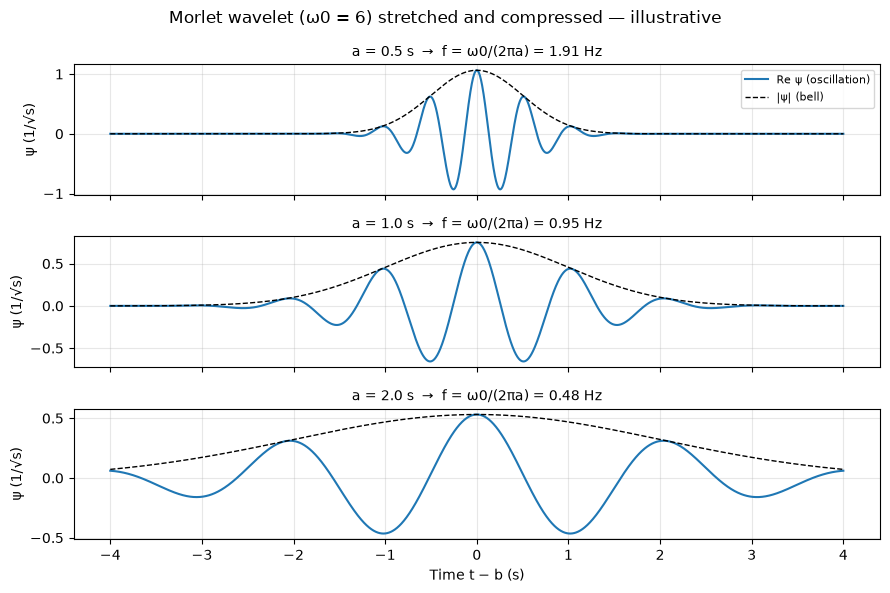

In [6]:
# Real part of the Morlet wavelet at three scales (illustrative)
w0 = 6.0
t = np.linspace(-4, 4, 2000)            # time around the wavelet center, s
scales = [0.5, 1.0, 2.0]                # scale a, s

fig, axes = plt.subplots(len(scales), 1, figsize=(9, 6), sharex=True)
for ax, a in zip(axes, scales):
    psi = scaled_wavelet(t, a, b=0.0, w0=w0)
    f = w0 / (2 * np.pi * a)            # Eq. 7
    ax.plot(t, psi.real, color="C0", label="Re ψ (oscillation)")
    ax.plot(t, np.abs(psi), "k--", lw=1, label="|ψ| (bell)")
    ax.set_ylabel("ψ (1/√s)")
    ax.set_title(f"a = {a} s  →  f = ω0/(2πa) = {f:.2f} Hz", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time t − b (s)")
fig.suptitle("Morlet wavelet (ω0 = 6) stretched and compressed — illustrative")
fig.tight_layout()
plt.show()

**Figura 5.** Parte real de la wavelet Morlet a tres escalas (ilustrativo): con $a$ pequeña la wavelet se comprime y oscila rápido (frecuencia alta); con $a$ grande se estira y oscila lento (frecuencia baja). La línea discontinua es la campana que la apaga hacia los lados.

*Paso 3: multiplicar y sumar.* Para una escala $a$ y un instante $b$, el coeficiente wavelet es:

$$W(a,b)=\frac{1}{\sqrt{a}}\int_{-\infty}^{\infty} x(t)\,\psi^{*}\!\left(\frac{t-b}{a}\right)dt \tag{8}$$

- $W(a,b)$: coeficiente wavelet (complejo) en la escala $a$ y el instante $b$; $|W(a,b)|$ es la **amplitud** de esa celda del mapa.
- $x(t)$: señal medida.
- $\psi$: wavelet madre (Ec. 6); $^{*}$ indica el conjugado complejo.
- $a$: escala, en s (fija la frecuencia, Ec. 7).
- $b$: desplazamiento en el tiempo: instante donde se centra la wavelet, en s.
- $1/\sqrt{a}$: normalización para que la wavelet tenga la misma energía en todas las escalas.
- $\int \dots\, dt$: multiplicar punto por punto la señal por la wavelet y sumar.

En palabras: mide cuánto se parece la señal, alrededor del instante $b$, a una oscilación de la frecuencia que corresponde a la escala $a$.

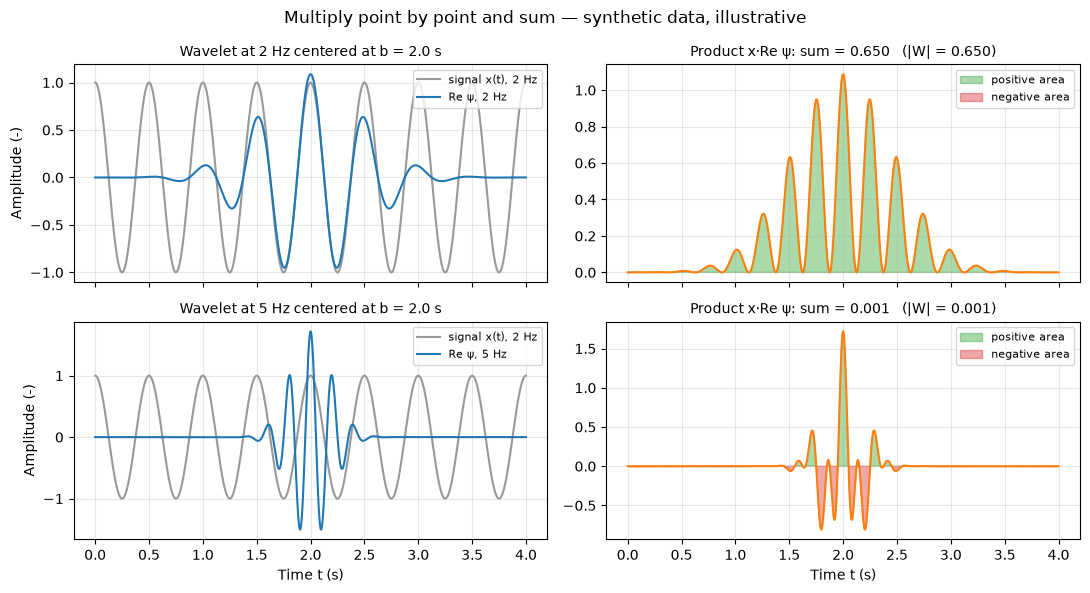

In [7]:
# "Multiply and sum": cosine at 2 Hz vs wavelets at 2 Hz and 5 Hz (illustrative)
dt = 0.001
t = np.arange(0, 4, dt)                 # time, s
f_signal = 2.0                          # signal frequency, Hz
x = np.cos(2 * np.pi * f_signal * t)
b = 2.0                                 # wavelet center, s

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for row, f_wav in enumerate([2.0, 5.0]):
    a = scale_for_freq(f_wav, w0=6.0)
    psi = scaled_wavelet(t, a, b, w0=6.0)
    product = x * psi.real
    total = product.sum() * dt                       # real part of Eq. 8
    W = (x * np.conj(psi)).sum() * dt                # full complex Eq. 8
    ax_l, ax_r = axes[row]
    ax_l.plot(t, x, color="0.6", label="signal x(t), 2 Hz")
    ax_l.plot(t, psi.real, color="C0", label=f"Re ψ, {f_wav:.0f} Hz")
    ax_l.set_ylabel("Amplitude (-)")
    ax_l.set_title(f"Wavelet at {f_wav:.0f} Hz centered at b = {b} s", fontsize=10)
    ax_l.legend(loc="upper right", fontsize=8)
    ax_r.plot(t, product, color="C1")
    ax_r.fill_between(t, product, where=product > 0, color="C2", alpha=0.4, label="positive area")
    ax_r.fill_between(t, product, where=product < 0, color="C3", alpha=0.4, label="negative area")
    ax_r.set_title(f"Product x·Re ψ: sum = {total:.3f}   (|W| = {abs(W):.3f})", fontsize=10)
    ax_r.legend(loc="upper right", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Time t (s)")
fig.suptitle("Multiply point by point and sum — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 6.** Multiplicar y sumar (ilustrativo, datos sintéticos): con la wavelet a la misma frecuencia de la señal (2 Hz, arriba) el producto es casi siempre positivo y la suma es grande; con la wavelet a otra frecuencia (5 Hz, abajo) el producto alterna signo, las áreas se cancelan y la suma es casi cero.

- La suma de la gráfica usa solo la parte real de $\psi$; $|W|$ usa la wavelet compleja completa (Ec. 8). Con la wavelet compleja la amplitud $|W|$ no depende de si la wavelet queda en fase con la señal.

*Paso 4: el mapa.* Repetir la Ec. 8 para muchas escalas $a$ (frecuencias, Ec. 7) y muchos instantes $b$ llena el mapa $|W(a,b)|$. En la CWT la energía de una frecuencia queda **repartida** en una franja ancha de escalas vecinas. La SSWT la reasigna en dos pasos:

$$\omega(a,b)=\frac{-i\,\partial_b W(a,b)}{W(a,b)} \tag{9}$$

- $\omega(a,b)$: frecuencia instantánea de la celda $(a,b)$, en rad/s: la frecuencia a la que realmente oscila la señal en esa celda.
- $\partial_b W(a,b)$: derivada del coeficiente respecto al tiempo $b$.
- $W(a,b)$: coeficiente wavelet (Ec. 8).
- $i$: unidad imaginaria.

En palabras: la fase de $W$ gira a la velocidad de la oscilación de la señal; derivarla en el tiempo da esa frecuencia, aunque la celda esté en una escala vecina.

$$T(f_l,b)=\sum_{a\,:\;\omega(a,b)/2\pi\,\approx\,f_l} W(a,b) \tag{10}$$

- $T(f_l,b)$: valor del mapa sincro-comprimido en la frecuencia $f_l$ (Hz) y el instante $b$.
- $f_l$: cada una de las frecuencias (filas) del mapa nuevo.
- La suma recorre solo las escalas $a$ cuya frecuencia instantánea (Ec. 9, pasada a Hz) cae en $f_l$.
- Expresión conceptual: se omiten las constantes de normalización.

En palabras: la energía de todas las celdas que "dicen" oscilar a $f_l$ se junta en la fila $f_l$; la franja ancha de la CWT se comprime en una línea delgada, y por eso el mapa sale más nítido.

**Ejemplo sintético.** Un carro cruza una viga simplemente apoyada de $L=100$ m a $v=20$ m/s (cruce de 5 s). Mide la vibración del puente en el segundo modo, con $f=1.3$ Hz y forma modal $\phi(x)=\sin(2\pi x/L)$:

$x(t)=|\phi(v\,t)|\cos(2\pi f t)+\text{ruido}$

- La amplitud que ve el carro sube y baja según la forma modal en el punto donde está.
- El eje de tiempo se pasa a posición con $x = v\,t$ (lo que en la práctica da el GPS; ver el apartado siguiente).
- Se usa la Morlet analítica de `ssqueezepy` con $\omega_0 = 3$ (en `ssqueezepy`, `mu`) en vez de 6: la wavelet es más corta y sigue mejor los cambios de amplitud en un cruce de solo 5 s, a cambio de menos resolución en frecuencia. Es una elección para este ejemplo, no un valor del artículo.

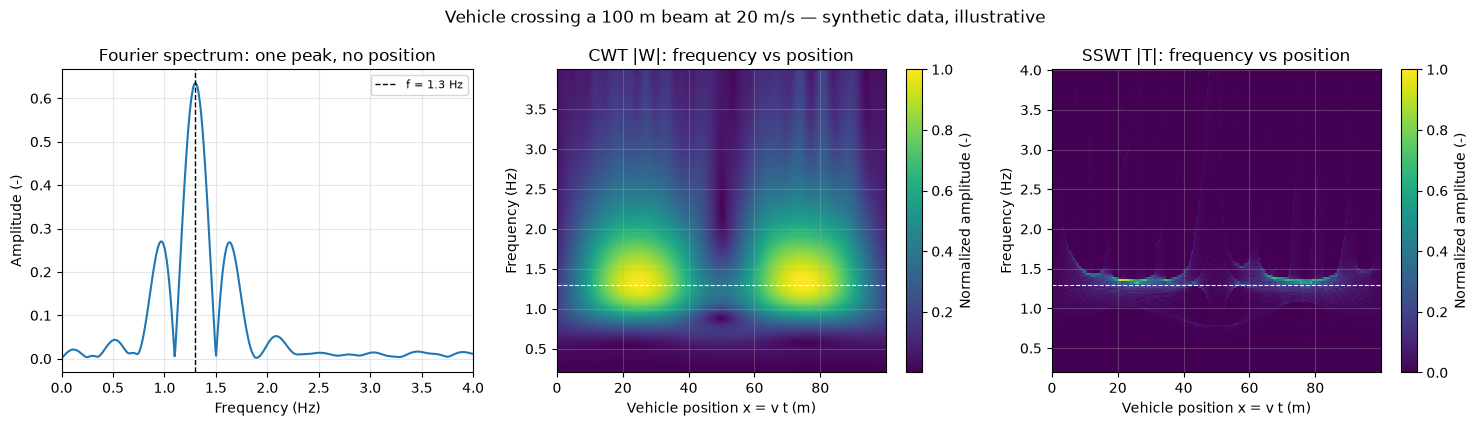

In [8]:
# Synthetic drive-by signal: vehicle crossing a 100 m simply supported beam
L = 100.0                               # span length, m
v = 20.0                                # vehicle speed, m/s
f_mode = 1.3                            # frequency of mode 2, Hz
fs = 100.0                              # sampling rate, Hz
noise_std = 0.1                         # noise standard deviation (-)

t = np.arange(0, L / v, 1 / fs)         # time, s
pos = v * t                             # vehicle position, m (x = v t)
phi_true = np.sin(2 * np.pi * pos / L)  # mode 2 shape
x = np.abs(phi_true) * np.cos(2 * np.pi * f_mode * t) + noise_std * rng.standard_normal(t.size)

# Fourier amplitude spectrum (zero-padded for a smooth curve)
n_fft = 2 ** 14
spec = np.abs(np.fft.rfft(x, n=n_fft)) * 2 / t.size
freqs_fft = np.fft.rfftfreq(n_fft, 1 / fs)

# CWT and SSWT with the analytic Morlet wavelet
wavelet = Wavelet(("morlet", {"mu": 3}))
Wx, scales_cwt = cwt(x, wavelet, fs=fs, nv=32, padtype="zero")
freqs_cwt = scale_to_freq(scales_cwt, wavelet, N=2 ** 14, fs=fs)   # Eq. 7 for this wavelet
Tx, _, freqs_ssq, _ = ssq_cwt(x, wavelet, fs=fs, nv=32, padtype="zero")

f_max = 4.0                             # upper frequency shown, Hz
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(freqs_fft, spec, color="C0")
axes[0].axvline(f_mode, color="k", ls="--", lw=1, label=f"f = {f_mode} Hz")
axes[0].set_xlim(0, f_max)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("Fourier spectrum: one peak, no position")
axes[0].legend(fontsize=8)

for ax, Z, fr, name in [(axes[1], Wx, freqs_cwt, "CWT |W|"), (axes[2], Tx, freqs_ssq, "SSWT |T|")]:
    A = np.abs(Z) / np.abs(Z).max()     # normalized amplitude
    keep = fr <= f_max
    mesh = ax.pcolormesh(pos, fr[keep], A[keep], shading="auto", cmap="viridis")
    ax.axhline(f_mode, color="w", ls="--", lw=0.8)
    ax.set_xlabel("Vehicle position x = v t (m)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"{name}: frequency vs position")
    fig.colorbar(mesh, ax=ax, label="Normalized amplitude (-)")
fig.suptitle("Vehicle crossing a 100 m beam at 20 m/s — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 7.** Señal sintética de un carro que cruza una viga de 100 m (ilustrativo): el espectro de Fourier (izquierda) solo muestra un pico cerca de 1.3 Hz, sin decir dónde está; la CWT (centro) muestra esa frecuencia a lo largo de la posición, pero en una franja ancha; la SSWT (derecha) la concentra en una línea delgada y se ve dónde la amplitud crece o cae a cero.

- En los dos mapas la amplitud baja casi a cero en $x \approx 50$ m: ahí está el nodo del segundo modo.
- Fourier no puede mostrarlo porque promedia toda la señal; la wavelet sí, porque mira la señal por ventanas.
- La línea de la SSWT queda ligeramente por encima de 1.3 Hz (≈ 1.35 Hz); por eso, para la forma modal se promedia una banda alrededor de la frecuencia y no una sola fila del mapa.

**Cómo se usa para la forma modal**

- Con el **GPS** se cambia el tiempo por la posición del carro: $x = v\,t$ si la velocidad es constante; en general, la posición GPS en cada instante.
- Se toma la **franja de la frecuencia del modo** (aquí $1.3 \pm 0.3$ Hz) y se promedia su amplitud a lo largo del puente. La curva resultante, normalizada a máximo 1, es la forma modal estimada.

RMS error vs |phi|: 0.053
RMS error vs phi (with sign): 0.981


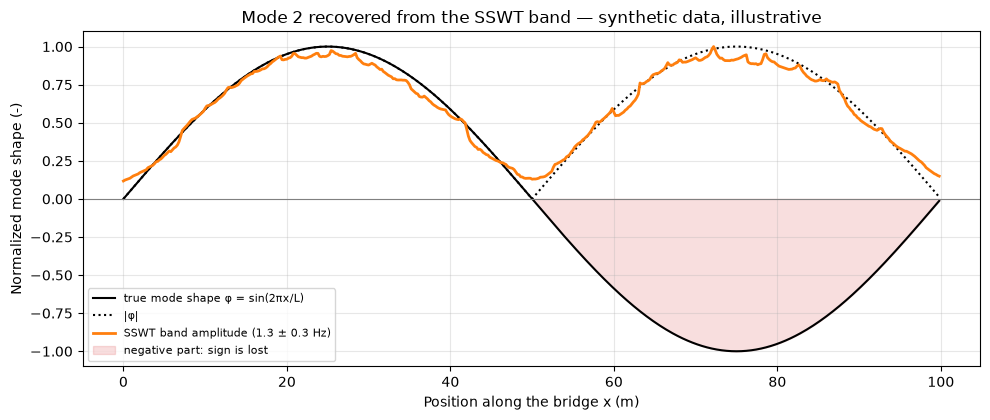

In [9]:
# Mode shape from the SSWT: mean amplitude in the band around the mode frequency
half_band = 0.3                         # half width of the frequency band, Hz
band = np.abs(freqs_ssq - f_mode) <= half_band
amp_band = np.abs(Tx[band]).mean(axis=0)
phi_est = amp_band / amp_band.max()     # normalized to max = 1

rms_abs = np.sqrt(np.mean((phi_est - np.abs(phi_true)) ** 2))
rms_signed = np.sqrt(np.mean((phi_est - phi_true) ** 2))
print(f"RMS error vs |phi|: {rms_abs:.3f}")
print(f"RMS error vs phi (with sign): {rms_signed:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos, phi_true, "k-", lw=1.5, label="true mode shape φ = sin(2πx/L)")
ax.plot(pos, np.abs(phi_true), "k:", lw=1.5, label="|φ|")
ax.plot(pos, phi_est, color="C1", lw=2, label=f"SSWT band amplitude ({f_mode} ± {half_band} Hz)")
ax.fill_between(pos, phi_true, 0, where=phi_true < 0, color="C3", alpha=0.15,
                label="negative part: sign is lost")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Normalized mode shape (-)")
ax.set_title("Mode 2 recovered from the SSWT band — synthetic data, illustrative")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 8.** Amplitud promedio de la SSWT en la banda de 1.3 Hz a lo largo de la posición, comparada con la forma modal verdadera (ilustrativo, datos sintéticos): la curva sigue a $|\phi|$, pero en el tramo de 50 a 100 m, donde la forma real es negativa, sale positiva. Se recupera la forma en valor absoluto y se pierde el signo.

- El error RMS respecto a $|\phi|$ es pequeño; respecto a $\phi$ con signo es grande, porque todo el tramo negativo sale reflejado hacia arriba.
- Para recuperar el signo hace falta otra información (por ejemplo, la fase); la amplitud por sí sola no la tiene.

**Ventajas**

- Funciona con señales cortas y no estacionarias.
- Da frecuencia y posición a la vez.

**Desventajas**

- Para formas modales hay que conocer de antemano la frecuencia del modo.
- La amplitud no tiene signo: la forma modal sale en valor absoluto.
- No separa la respuesta del puente de la del vehículo.

**Artículos:** Dabbaghchian et al. (2025).

> **Nota de fuentes.** La explicación general de cómo funciona la wavelet es conocimiento general, no del artículo. Del artículo vienen: el uso de la SSWT con wavelet madre Morlet analítica y los límites para formas modales (frecuencia conocida de antemano, forma modal absoluta).

**Entradas y salidas**

- **Entrada:**
  - Una señal de aceleración contra tiempo, de un solo canal (vertical u horizontal), con su frecuencia de muestreo.
  - La wavelet madre escogida (por ejemplo, Morlet).
  - Para formas modales, además: la posición del vehículo en cada instante (GPS) y la frecuencia del modo, conocida de antemano.
- **Salida:**
  - Un mapa tiempo-frecuencia de coeficientes complejos $W(a,b)$; su magnitud $|W|$ es la amplitud de cada celda.
  - Con el GPS, el mismo mapa en función de la posición sobre el puente.
- **Qué se obtiene o interpreta:**
  - Qué frecuencias tiene la señal y en qué momento aparecen.
  - Cómo cambia la amplitud de una frecuencia a lo largo del recorrido.
  - Tomando la franja de la frecuencia del modo y promediando muchos viajes, la forma modal en valor absoluto (sin signo).

[↑ Volver al índice](#indice)